FASE 11: m=2, s=2, K=3, T=6000, 100 cadenas, con_puntaje. Estrategias posibles: 19683


N=     101  gamma=0.089109  N*s/estrategias=   0.01  exito=0.2760 (azar 0.2852)  M(1)=9.45e-07  M(3)=1.88e-02  contraste 27/54/81 = 2.9 / 2.3 / 2.3  C(6)=0.608  vacias=0  -> CON picos  [leido del .npz, 1 s]


N=    1001  gamma=0.008991  N*s/estrategias=   0.10  exito=0.2756 (azar 0.3179)  M(1)=6.02e-07  M(3)=3.56e-02  contraste 27/54/81 = 10.1 / 9.3 / 9.3  C(6)=1.235  vacias=0  -> CON picos  [leido del .npz, 1 s]


N=    5000  gamma=0.001800  N*s/estrategias=   0.51  exito=0.2772 (azar 0.3264)  M(1)=7.04e-07  M(3)=3.39e-02  contraste 27/54/81 = 8.6 / 8.7 / 8.8  C(6)=1.214  vacias=0  -> CON picos  [leido del .npz, 1 s]


N=    9842  gamma=0.000914  N*s/estrategias=   1.00  exito=0.2778 (azar 0.3284)  M(1)=5.88e-07  M(3)=3.40e-02  contraste 27/54/81 = 8.4 / 8.4 / 8.5  C(6)=1.226  vacias=0  -> CON picos  [leido del .npz, 1 s]


N=   19684  gamma=0.000457  N*s/estrategias=   2.00  exito=0.2781 (azar 0.3298)  M(1)=6.13e-07  M(3)=3.24e-02  contraste 27/54/81 = 10.3 / 8.7 / 9.0  C(6)=1.223  vacias=0  -> CON picos  [leido del .npz, 1 s]


... (2 outputs left out)

N=  400000  gamma=0.000023  N*s/estrategias=  40.64  exito=0.2780 (azar 0.3326)  M(1)=5.38e-07  M(3)=3.05e-02  contraste 27/54/81 = 8.8 / 8.4 / 8.3  C(6)=1.157  vacias=0  -> CON picos  [leido del .npz, 1 s]


N= 1000000  gamma=0.000009  N*s/estrategias= 101.61  exito=0.2784 (azar 0.3328)  M(1)=5.87e-07  M(3)=3.32e-02  contraste 27/54/81 = 8.9 / 8.5 / 8.1  C(6)=1.205  vacias=0  -> CON picos  [leido del .npz, 1 s]



Guardado: csv\Fase11_resumen_con_puntaje_m2_s2_T6000_N101-a-1000000_9valores.csv
Guardado: csv\Fase11_Md_promedio_con_puntaje_m2_s2_T6000_N101-a-1000000_9valores.csv

Graficas:


  Guardado: graficas\Fase11_Md_con_puntaje_m2_s2_T6000_N101-a-1000000_9valores.png


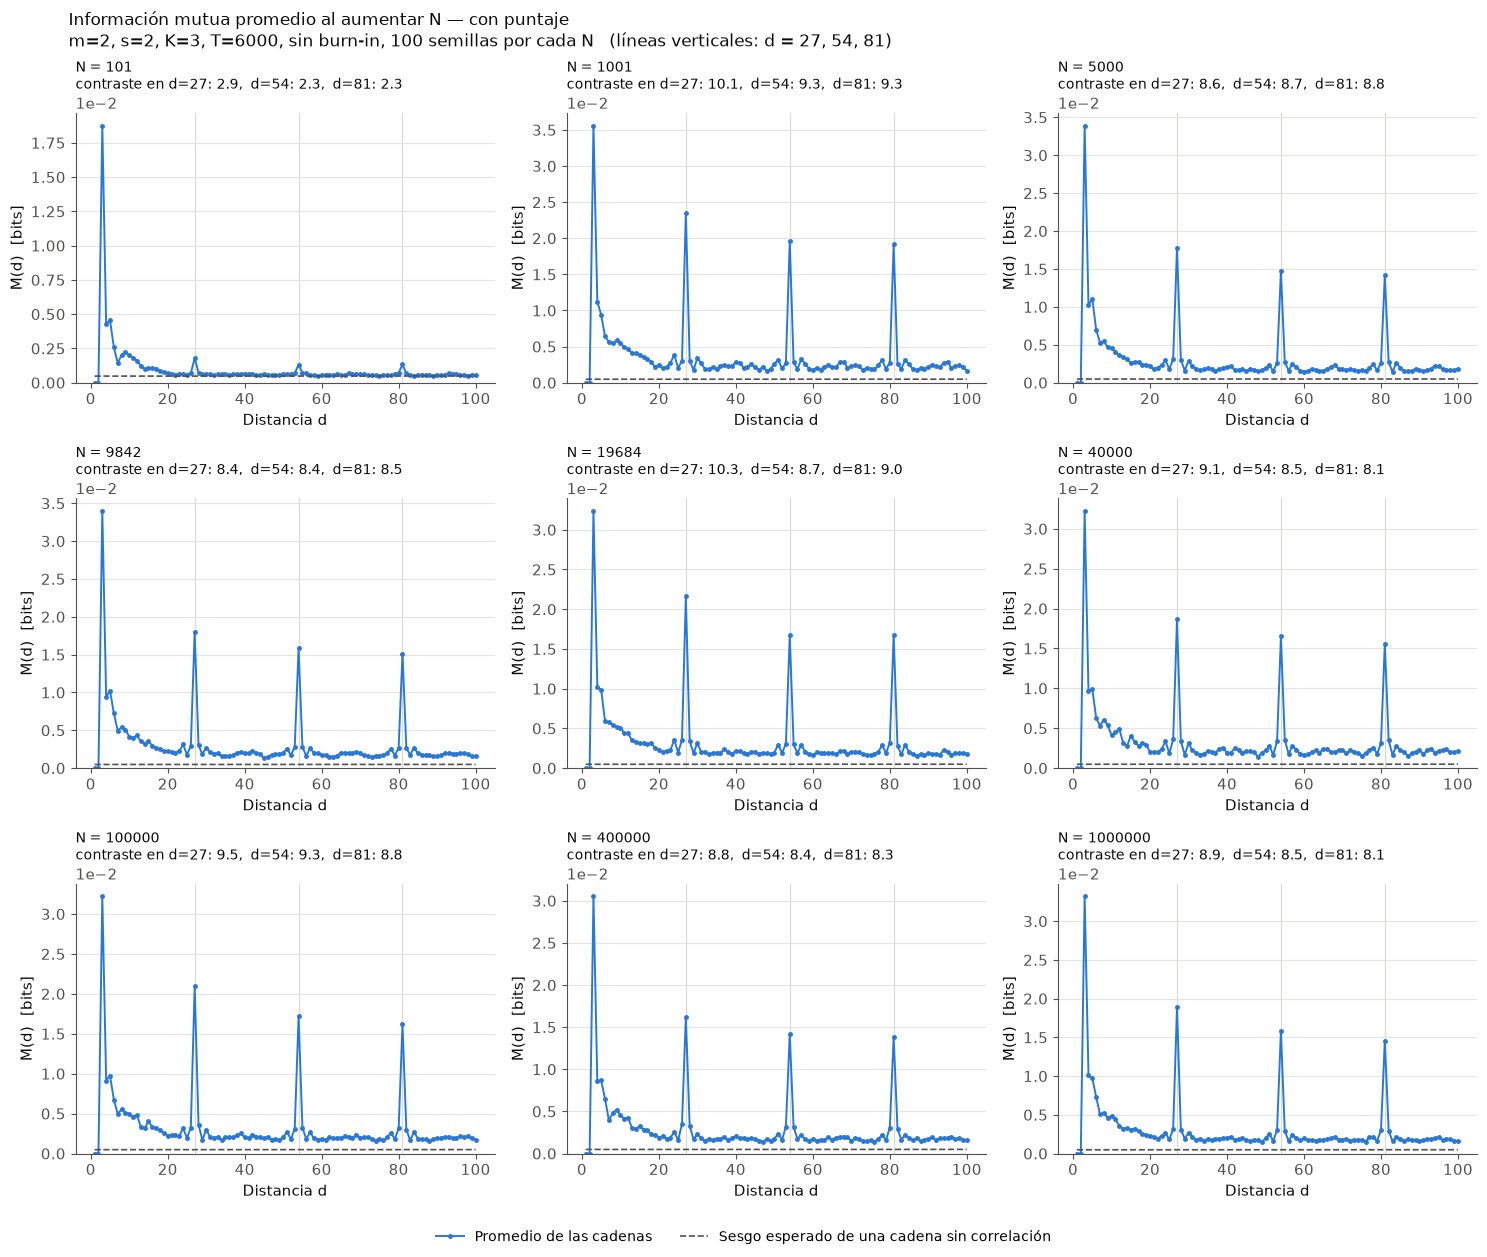

  Guardado: graficas\Fase11_espectro_con_puntaje_m2_s2_T6000_N101-a-1000000_9valores.png


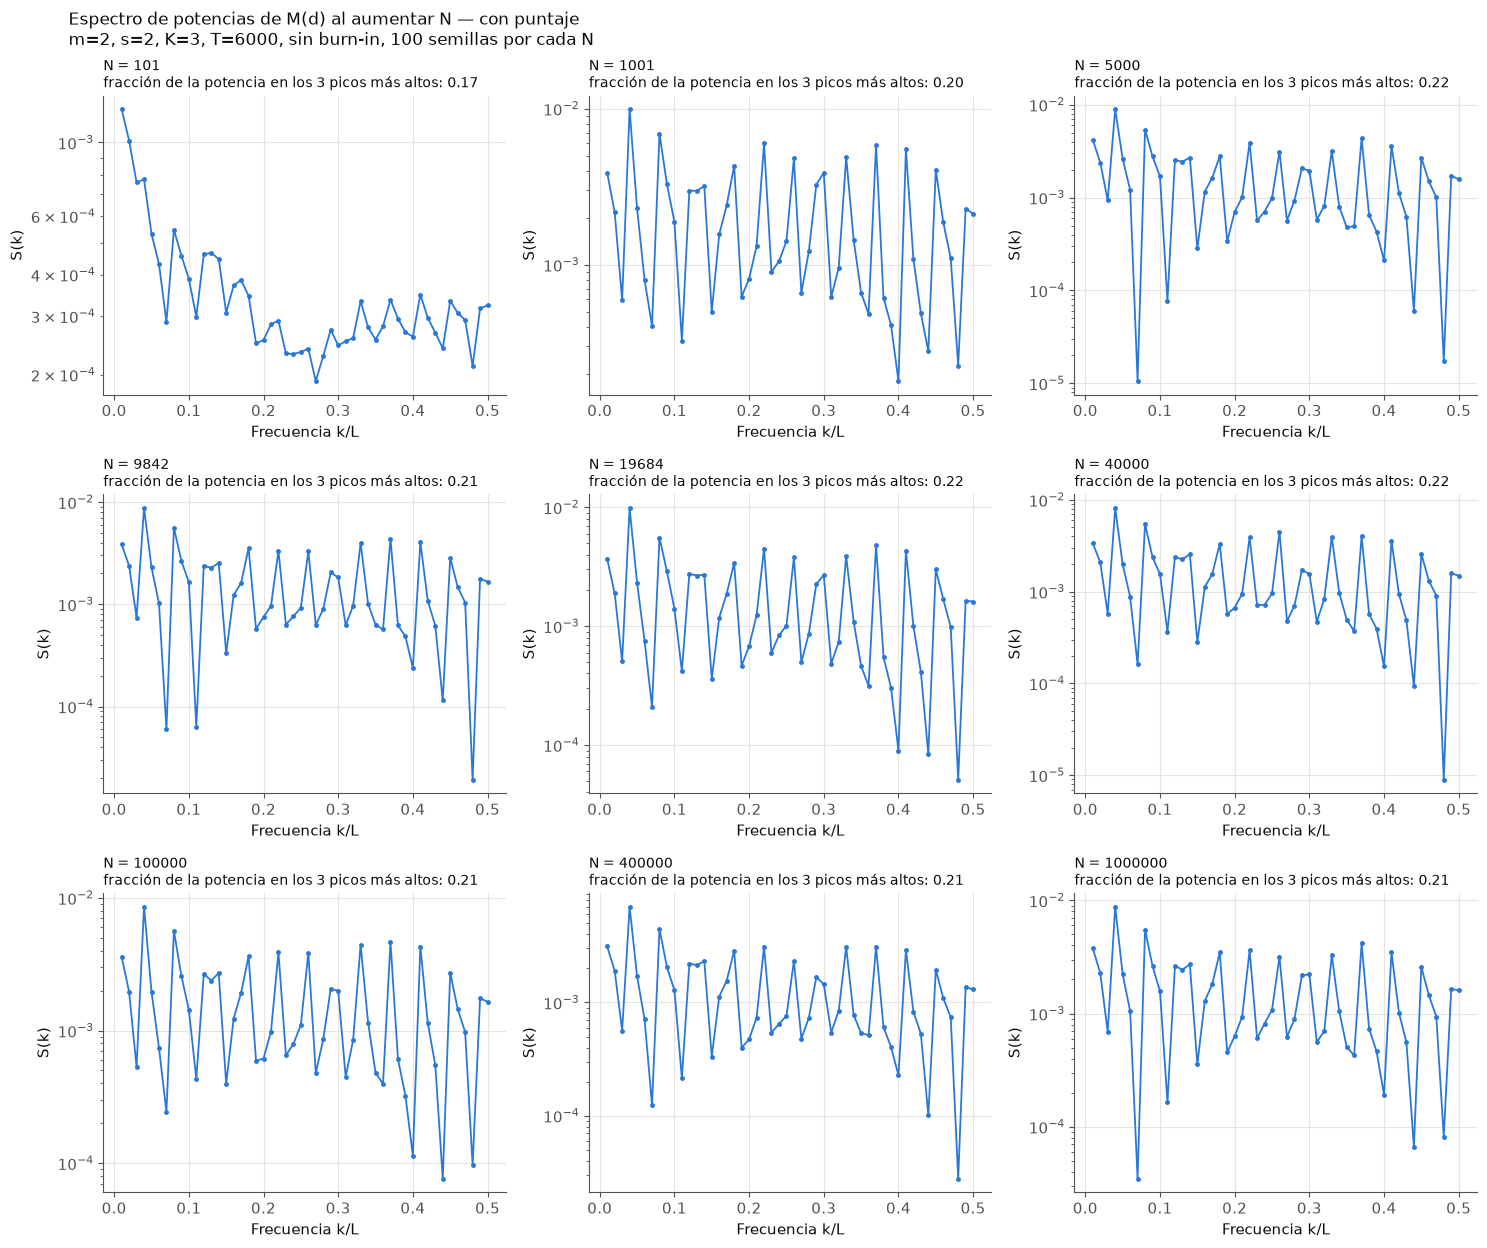

  Guardado: graficas\Fase11_CK_con_puntaje_m2_s2_T6000_N101-a-1000000_9valores.png


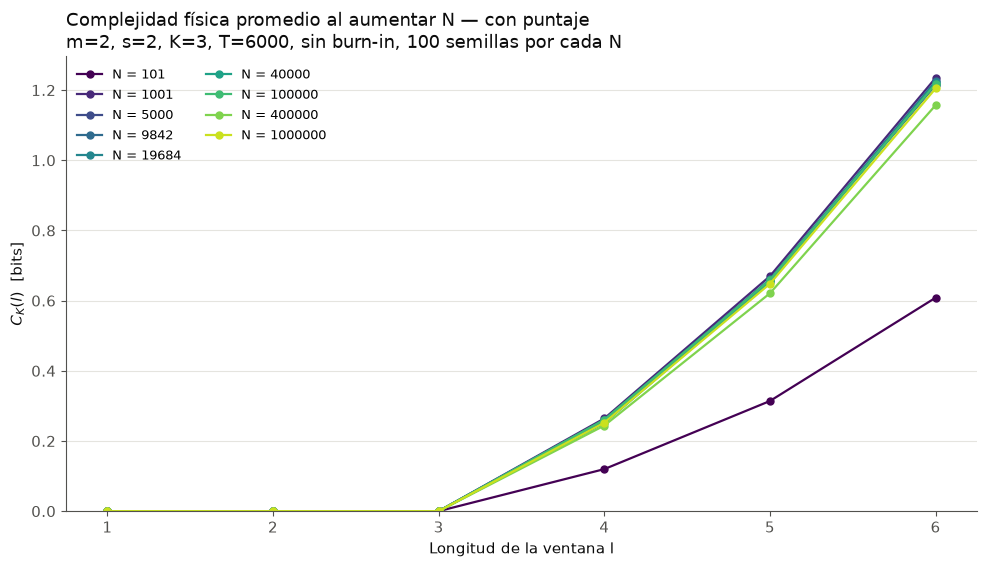

  Guardado: graficas\Fase11_resumen_con_puntaje_m2_s2_T6000_N101-a-1000000_9valores.png


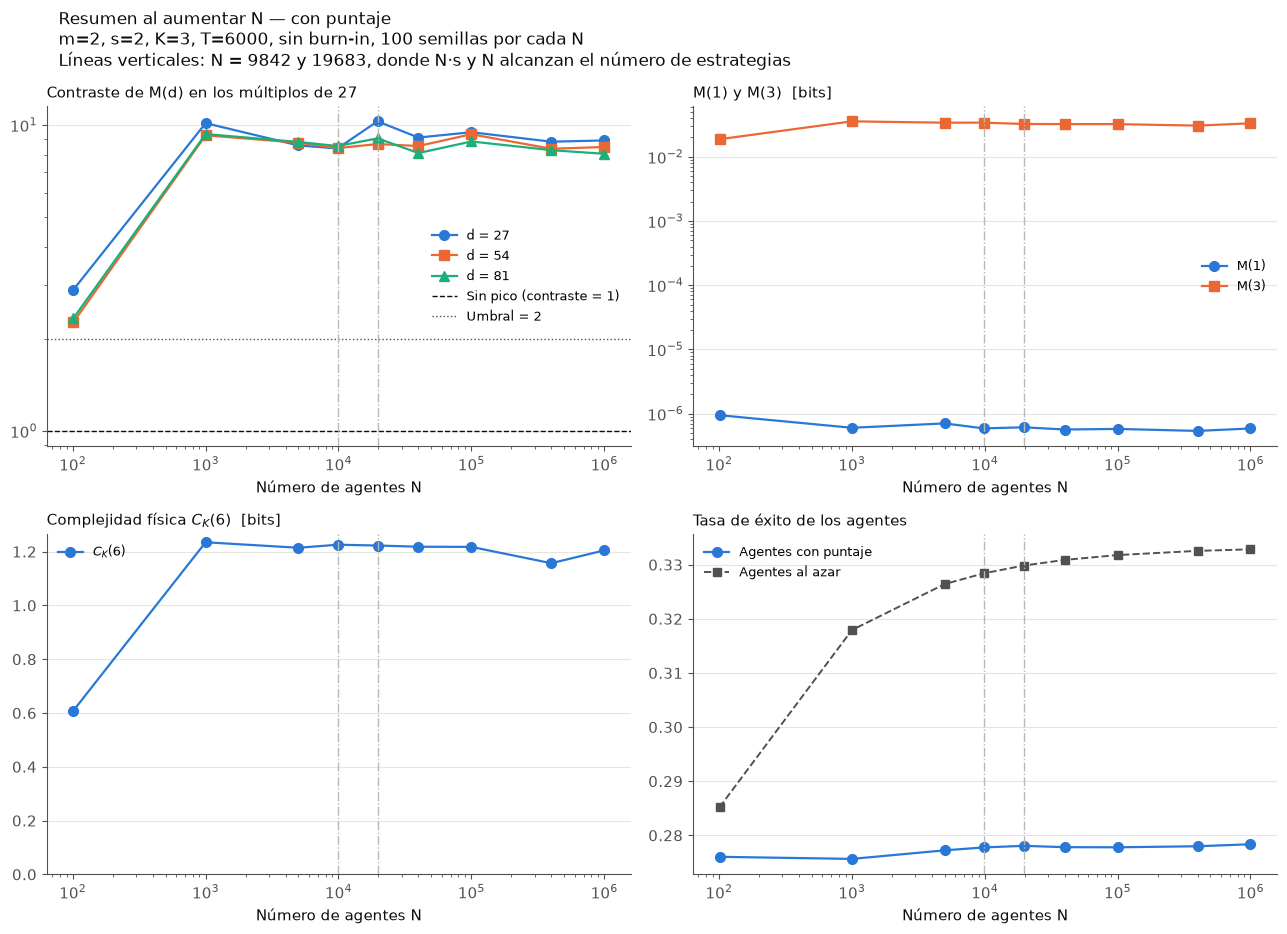


Valores de N SIN picos periodicos (todos los contrastes < 2): ninguno
Listo. Tiempo total: 0.2 min


In [1]:
"""
FASE 11 - Busqueda de la fase gaseosa al aumentar el numero de agentes
======================================================================
Tesis: Complejidad e informacion en un minority game con opcion de abstencion

Alfabeto: 0 = comprar, 1 = vender, 2 = abstenerse

Juego: m = 2, s = 2, K = 3, con puntaje. El espacio de estrategias tiene
K^(K^m) = 3^9 = 19683 estrategias. Se aumenta N hasta superar ese numero.

Que hace este codigo, para cada N de LISTA_N:
  1. Simula 100 cadenas (mismo nucleo que la Fase 9, sin cambios) y guarda la
     serie de ganadores y los conteos N0, N1, N2 en UN archivo comprimido .npz.
     Si el archivo ya existe y REUTILIZAR_DATOS = True, lo lee y no simula.
  2. Calcula M(d), d = 1..100, y C_K(l), l = 1..6, de cada cadena, y promedia.
  3. Mide la periodicidad: el "contraste" de M(d) en d = 27, 54 y 81 (los
     multiplos de K^(m+1)) es M(d) dividido entre la mediana de sus vecinos.
     Contraste cerca de 1 = no hay pico. Tambien calcula el espectro de
     potencias de M(d) y que fraccion de su potencia esta en los 3 picos
     mas altos.
  Criterio (decision de Hector): se considera fase gaseosa si no hay
  periodicidad, es decir, si los tres contrastes son menores que
  UMBRAL_CONTRASTE.

Se guardan solo las graficas, dos CSV pequenos de resumen y un .npz por N.
gamma = K^m / N va en el CSV, no en los titulos.

Sin cambios: regla_ganador, simular_con_puntaje, informacion_mutua y
terminar_figura (Fase 9); complejidad_fisica y resumir (Fase 8);
sesgo_esperado y exito_al_azar (Fase 7); espectro_potencias (Fase 9).
"""

import os
import time

import numpy as np
import matplotlib.pyplot as plt

try:
    from scipy.stats import t as t_student
except ImportError:
    t_student = None
T_95 = 1.984

try:
    from joblib import Parallel, delayed
    HAY_JOBLIB = True
except ImportError:
    HAY_JOBLIB = False


# =====================================================================
# OPCIONES
# =====================================================================
# Las graficas SIEMPRE se muestran en el notebook.
DESCARGAR_GRAFICAS = True     # True = ademas se guardan como PNG
GUARDAR_CSV        = True     # True = se guardan los dos CSV de resumen
GUARDAR_DATOS      = True     # True = un .npz comprimido por N (ganadores y conteos)
REUTILIZAR_DATOS   = True     # True = si el .npz de un N ya existe, no se vuelve a simular
OPCION_VACIA_GANA  = False    # regla nueva, como en la Fase 9

CARPETA_CSV      = "csv"
CARPETA_GRAFICAS = "graficas"
CARPETA_DATOS    = "datos"

#   -1 -> usa TODOS los nucleos     1 -> un solo nucleo
N_NUCLEOS = -1


# =====================================================================
# PARAMETROS
# =====================================================================
SEMILLA_MAESTRA = 1907443528
N_CADENAS = 100

M       = 2      # memoria
S       = 2      # estrategias por agente
K       = 3      # tamano del alfabeto
T       = 6000   # turnos registrados, desde el primero (sin burn-in)
LISTA_N = [101, 1001, 5000, 9842, 19684, 40000, 100000, 400000, 1000000]

D_MAX   = 100
L_MAX   = 6
NIVEL   = 0.95

PERIODO          = K ** (M + 1)             # 27: los picos salen en sus multiplos
DISTANCIAS_PICO  = [PERIODO, 2 * PERIODO, 3 * PERIODO]
VECINOS          = 7                        # vecinos a cada lado para la mediana
UMBRAL_CONTRASTE = 2.0                      # contraste >= 2 se cuenta como pico
N_ESTRATEGIAS    = K ** (K ** M)            # 19683

ETIQUETA = "con_puntaje"


# =====================================================================
# NUCLEO DEL JUEGO  (igual que en la Fase 9)
# =====================================================================
def regla_ganador(conteos, rng, opcion_vacia_gana):
    """Devuelve el simbolo ganador y si se decidio con moneda.

    Regla vieja: gana el minimo de las K opciones (una vacia cuenta).
    Regla nueva: gana el minimo entre las opciones con al menos un agente.
    El desempate usa rng.choice igual que el codigo de la Fase 2, asi que
    se consume la misma cantidad de numeros aleatorios en las dos reglas.
    """
    if opcion_vacia_gana:
        minimo = conteos.min()
    else:
        minimo = conteos[conteos > 0].min()
    empatados = np.flatnonzero(conteos == minimo)
    return int(rng.choice(empatados)), len(empatados) > 1


def simular_con_puntaje(N, m, s, K, T, semilla, opcion_vacia_gana):
    """Corre una partida con las reglas del codigo base, sin burn-in.

    Cada agente tiene s estrategias. En cada ciclo usa la que tiene mas
    puntos (los empates se rompen al azar), y al final del ciclo todas
    las estrategias que habrian acertado al ganador reciben un punto.

    Devuelve la serie de ganadores, cuantas veces acerto cada agente, los
    conteos N0, N1, N2 de cada turno y si el turno se decidio con moneda.
    """
    rng = np.random.default_rng(semilla)
    N_HIST = K ** m

    # --- agentes (igual que el codigo base) ---
    # estrategias[i, j, h] = accion que la estrategia j del agente i
    #                        recomienda ante la historia con indice h
    estrategias = rng.integers(0, K, size=(N, s, N_HIST))

    # puntajes[i, j] = puntos virtuales (casos de exito) de esa estrategia
    puntajes = np.zeros((N, s))

    # --- memoria: los m datos que el mercado tiene "al nacer" ---
    historia = rng.integers(0, K, size=m)

    pesos = K ** np.arange(m - 1, -1, -1)   # convierte historia -> indice
    indices = np.arange(N)

    serie_ganadores = np.zeros(T, dtype=int)
    conteos_por_turno = np.zeros((T, K), dtype=np.int32)   # N0, N1, N2
    con_moneda = np.zeros(T, dtype=bool)
    exitos_agente = np.zeros(N, dtype=int)

    for t in range(T):

        # 1. que situacion estan viendo los agentes
        idx = int(historia @ pesos)

        # 2. cada agente toma su estrategia con mas puntos.
        #    El ruido < 1 rompe empates al azar sin alterar el orden
        #    entre puntajes enteros distintos.
        mejor = np.argmax(puntajes + rng.random((N, s)) * 0.5, axis=1)

        # 3. consulta esa estrategia en la historia actual y actua
        acciones = estrategias[indices, mejor, idx]

        # 4. se cuenta cuantos eligieron cada opcion
        conteos = np.bincount(acciones, minlength=K)

        # 5. gana la minoria (segun la regla elegida)
        ganador, hubo_moneda = regla_ganador(conteos, rng, opcion_vacia_gana)

        # 6. se premian TODAS las estrategias que hubieran acertado,
        #    se hayan jugado o no (regla del codigo base / PRE 62).
        puntajes += (estrategias[:, :, idx] == ganador)

        # 7. registrar desde el primer ciclo
        serie_ganadores[t] = ganador
        conteos_por_turno[t] = conteos
        con_moneda[t] = hubo_moneda
        exitos_agente += (acciones == ganador)

        # 8. la memoria se desplaza: entra el ganador, sale el mas viejo
        historia = np.roll(historia, -1)
        historia[-1] = ganador

    return serie_ganadores, exitos_agente, conteos_por_turno, con_moneda


def correr_cadena(N, m, s, K, T, semilla, opcion_vacia_gana):
    """Una cadena: serie de ganadores (1 byte por turno) y conteos N0, N1, N2."""
    serie, _, conteos, _ = simular_con_puntaje(N, m, s, K, T, semilla, opcion_vacia_gana)
    return serie.astype(np.uint8), conteos


def correr_N(N, semillas, n_nucleos):
    """Todas las cadenas de un N. El resultado no depende del numero de nucleos."""
    if N % K == 0:
        raise ValueError(f"N = {N} es multiplo de {K}")
    if HAY_JOBLIB and n_nucleos != 1:
        bloque = Parallel(n_jobs=n_nucleos)(
            delayed(correr_cadena)(N, M, S, K, T, int(sem), OPCION_VACIA_GANA)
            for sem in semillas)
    else:
        bloque = [correr_cadena(N, M, S, K, T, int(sem), OPCION_VACIA_GANA)
                  for sem in semillas]
    return np.array([b[0] for b in bloque]), np.array([b[1] for b in bloque])


# =====================================================================
# MEDIDAS  (iguales que en las fases 7, 8 y 9)
# =====================================================================
def informacion_mutua(serie, d, K):
    """M(d) = sum_{a,b} P_ab(d) * log2[ P_ab(d) / (P_a * P_b) ]

    P_ab(d): probabilidad de encontrar el simbolo a y, d lugares despues,
             el simbolo b. Se estima contando todos los pares
             (serie[i], serie[i+d]) de la cadena.
    P_a:     densidad del simbolo a en la cadena completa (como dice
             Mansilla: "the density of the symbol alpha").

    La suma corre sobre los K*K = 9 pares (a, b). Los pares que nunca
    aparecen (P_ab = 0) no aportan, porque 0 * log(0) = 0.
    """
    x = serie[:-d]          # simbolo alpha
    y = serie[d:]           # simbolo beta, d lugares despues
    n_pares = len(x)

    # probabilidades conjuntas P_ab(d): matriz K x K
    conjunta = np.bincount(x * K + y, minlength=K * K).reshape(K, K) / n_pares

    # densidades P_a de cada simbolo en toda la cadena
    densidad = np.bincount(serie, minlength=K) / len(serie)
    producto = np.outer(densidad, densidad)      # P_a * P_b

    M_d = 0.0
    for a in range(K):
        for b in range(K):
            if conjunta[a, b] > 0:
                M_d += conjunta[a, b] * np.log2(conjunta[a, b] / producto[a, b])
    return M_d


def sesgo_esperado(K, n_pares):
    """Valor que da M(d) en una cadena SIN correlacion, solo por ser finita.

    Es aproximadamente (K-1)^2 / (2 * n * ln 2). Solo depende de T, asi
    que es la misma linea de referencia para todos los N.
    """
    return (K - 1) ** 2 / (2 * n_pares * np.log(2))


def exito_al_azar(N, K, n_muestras=200000, semilla=0):
    """Tasa de exito que tendrian N agentes eligiendo al azar.

    El 0.265 que imprimia el Segundo paso solo vale para N = 50. Aqui se
    calcula para cada N: se reparten N agentes al azar entre las K
    acciones muchas veces y se promedia la fraccion que queda en la
    accion ganadora (la de menos agentes).
    """
    rng = np.random.default_rng(semilla)
    conteos = rng.multinomial(N, [1 / K] * K, size=n_muestras)
    return (conteos.min(axis=1) / N).mean()


def complejidad_fisica(serie, l, K):
    """Devuelve C_K(l) y c_K(l) de una cadena de ganadores.

    Una ventana de longitud l recorre la cadena de uno en uno. Cada ventana
    se convierte en un numero (en base K) para contar cuantas veces aparece
    cada subcadena eta. Con esas frecuencias relativas p(eta):

        H(l)   = -sum p(eta) log2 p(eta)
        C_K(l) = l*log2(K) - H(l)
        c_K(l) = C_K(l) / (l*log2(K))
    """
    ventanas = np.lib.stride_tricks.sliding_window_view(serie, l)
    pesos = K ** np.arange(l - 1, -1, -1)
    codigos = ventanas @ pesos
    conteos = np.bincount(codigos, minlength=K ** l)

    p = conteos[conteos > 0] / len(codigos)
    H = -np.sum(p * np.log2(p))

    maximo = l * np.log2(K)
    C = maximo - H
    return C, C / maximo


def resumir(tabla, t_crit):
    """Promedio sobre las cadenas (filas), con su intervalo de confianza."""
    media = tabla.mean(axis=0)
    desv = tabla.std(axis=0, ddof=1)
    error_est = desv / np.sqrt(tabla.shape[0])
    return {"media": media, "desv": desv, "error_est": error_est,
            "ic_inf": media - t_crit * error_est,
            "ic_sup": media + t_crit * error_est}


def espectro_potencias(Md):
    """Ec. (4) del protocolo con u = 1: S(k) = |sum_d M(d) exp(-i 2 pi (k/L) d)|^2,
    para k = 1, ..., L/2. Devuelve la frecuencia k/L y S(k)."""
    L = len(Md)
    d = np.arange(1, L + 1)
    k = np.arange(1, L // 2 + 1)
    return k / L, np.abs(np.exp(-2j * np.pi * np.outer(k, d) / L) @ Md) ** 2


def contraste(Md, d0):
    """M(d0) dividido entre la mediana de M(d) en sus vecinos (sin contar d0)."""
    vecinos = [d for d in range(d0 - VECINOS, d0 + VECINOS + 1)
               if d != d0 and 1 <= d <= len(Md)]
    return Md[d0 - 1] / np.median(Md[np.array(vecinos) - 1])


# =====================================================================
# GRAFICAS
# =====================================================================
AZUL = "#2a78d6"
NARANJA = "#eb6834"
GRIS = "#52514e"
TINTA = "#0b0b0b"
SUBTITULO = f"m={M}, s={S}, K={K}, T={T}, sin burn-in, {N_CADENAS} semillas por cada N"


def terminar_figura(fig, archivo):
    if DESCARGAR_GRAFICAS:
        ruta = os.path.join(CARPETA_GRAFICAS, archivo)
        fig.savefig(ruta, dpi=150)
        print(f"  Guardado: {ruta}", flush=True)
    plt.show()
    plt.close(fig)


def rejilla(n):
    columnas = 3
    filas = int(np.ceil(n / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(15, 3.9 * filas + 1), squeeze=False)
    for ax in ejes.ravel()[n:]:
        ax.set_visible(False)
    return fig, ejes.ravel()[:n]


def graficar_Md(resultados, distancias, referencia):
    fig, ejes = rejilla(len(LISTA_N))
    for ax, N in zip(ejes, LISTA_N):
        r = resultados[N]
        for d0 in DISTANCIAS_PICO:
            ax.axvline(d0, color="#d9d8d3", lw=0.8, zorder=0)
        ax.plot(distancias, r["Md"]["media"], color=AZUL, lw=1.4, marker="o", ms=2.5,
                label="Promedio de las cadenas")
        ax.plot(distancias, referencia, color=GRIS, lw=1.2, ls="--",
                label="Sesgo esperado de una cadena sin correlación")
        texto = ",  ".join(f"d={d0}: {c:.1f}" for d0, c in zip(DISTANCIAS_PICO, r["contrastes"]))
        ax.set_title(f"N = {N}\ncontraste en {texto}", loc="left", color=TINTA, fontsize=10)
        ax.set_xlabel("Distancia d")
        ax.set_ylabel("M(d)  [bits]")
        ax.set_ylim(bottom=0)
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
        ax.grid(axis="y", color="#e5e4df", lw=0.8)
    manijas, etiquetas = ejes[0].get_legend_handles_labels()
    fig.legend(manijas, etiquetas, frameon=False, loc="lower center", ncol=2, fontsize=10)
    fig.suptitle("Información mutua promedio al aumentar N — con puntaje\n" + SUBTITULO
                 + f"   (líneas verticales: d = {', '.join(map(str, DISTANCIAS_PICO))})",
                 x=0.05, ha="left", color=TINTA, fontsize=12)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    terminar_figura(fig, f"Fase11_Md_{BASE}.png")


def graficar_espectro(resultados):
    fig, ejes = rejilla(len(LISTA_N))
    for ax, N in zip(ejes, LISTA_N):
        r = resultados[N]
        ax.plot(r["f"], r["S"], color=AZUL, lw=1.3, marker="o", ms=2.5)
        ax.set_yscale("log")
        ax.set_title(f"N = {N}\nfracción de la potencia en los 3 picos más altos: "
                     f"{r['frac_picos']:.2f}", loc="left", color=TINTA, fontsize=10)
        ax.set_xlabel("Frecuencia k/L")
        ax.set_ylabel("S(k)")
        ax.grid(color="#e5e4df", lw=0.8)
    fig.suptitle("Espectro de potencias de M(d) al aumentar N — con puntaje\n" + SUBTITULO,
                 x=0.05, ha="left", color=TINTA, fontsize=12)
    fig.tight_layout()
    terminar_figura(fig, f"Fase11_espectro_{BASE}.png")


def graficar_CK(resultados, longitudes):
    colores = plt.cm.viridis(np.linspace(0, 0.92, len(LISTA_N)))
    fig, ax = plt.subplots(figsize=(10, 5.8))
    for N, color in zip(LISTA_N, colores):
        ax.plot(longitudes, resultados[N]["C"]["media"], color=color, lw=1.6, marker="o",
                ms=5, label=f"N = {N}")
    ax.set_xlabel("Longitud de la ventana l")
    ax.set_ylabel("$C_K(l)$  [bits]")
    ax.set_xticks(longitudes)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color="#e5e4df", lw=0.8)
    ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=9)
    ax.set_title("Complejidad física promedio al aumentar N — con puntaje\n" + SUBTITULO,
                 loc="left", color=TINTA)
    fig.tight_layout()
    terminar_figura(fig, f"Fase11_CK_{BASE}.png")


def graficar_resumen(resultados, azar):
    Ns = np.array(LISTA_N, dtype=float)
    fig, ejes = plt.subplots(2, 2, figsize=(13, 9.5))
    ax = ejes[0, 0]
    for i, (d0, color, marca) in enumerate(zip(DISTANCIAS_PICO, [AZUL, NARANJA, "#1baf7a"], "os^")):
        ax.plot(Ns, [resultados[N]["contrastes"][i] for N in LISTA_N], color=color,
                marker=marca, ms=7, lw=1.6, label=f"d = {d0}")
    ax.axhline(1, color=TINTA, lw=1, ls="--", label="Sin pico (contraste = 1)")
    ax.axhline(UMBRAL_CONTRASTE, color=GRIS, lw=1, ls=":", label=f"Umbral = {UMBRAL_CONTRASTE:g}")
    ax.set_yscale("log")
    ax.set_title("Contraste de M(d) en los múltiplos de 27", loc="left", color=TINTA, fontsize=11)
    ax = ejes[0, 1]
    for j, color, marca in ((0, AZUL, "o"), (2, NARANJA, "s")):
        ax.plot(Ns, [resultados[N]["Md"]["media"][j] for N in LISTA_N], color=color,
                marker=marca, ms=7, lw=1.6, label=f"M({j + 1})")
    ax.set_yscale("log")
    ax.set_title("M(1) y M(3)  [bits]", loc="left", color=TINTA, fontsize=11)
    ax = ejes[1, 0]
    ax.plot(Ns, [resultados[N]["C"]["media"][-1] for N in LISTA_N], color=AZUL, marker="o",
            ms=7, lw=1.6, label=f"$C_K({L_MAX})$")
    ax.set_ylim(bottom=0)
    ax.set_title(f"Complejidad física $C_K({L_MAX})$  [bits]", loc="left", color=TINTA, fontsize=11)
    ax = ejes[1, 1]
    ax.plot(Ns, [resultados[N]["exito"] for N in LISTA_N], color=AZUL, marker="o", ms=7,
            lw=1.6, label="Agentes con puntaje")
    ax.plot(Ns, [azar[N] for N in LISTA_N], color=GRIS, marker="s", ms=6, lw=1.4, ls="--",
            label="Agentes al azar")
    ax.set_title("Tasa de éxito de los agentes", loc="left", color=TINTA, fontsize=11)
    for ax in ejes.ravel():
        ax.axvline(N_ESTRATEGIAS / S, color="#b9b8b3", lw=1, ls="-.")
        ax.axvline(N_ESTRATEGIAS, color="#b9b8b3", lw=1, ls="-.")
        ax.set_xscale("log")
        ax.set_xlabel("Número de agentes N")
        ax.grid(axis="y", color="#e5e4df", lw=0.8)
        ax.legend(frameon=False, fontsize=9)
    fig.suptitle("Resumen al aumentar N — con puntaje\n" + SUBTITULO
                 + f"\nLíneas verticales: N = {N_ESTRATEGIAS // S + 1} y {N_ESTRATEGIAS}, "
                 "donde N·s y N alcanzan el número de estrategias",
                 x=0.05, ha="left", color=TINTA, fontsize=12)
    fig.tight_layout()
    terminar_figura(fig, f"Fase11_resumen_{BASE}.png")


# =====================================================================
# PROGRAMA PRINCIPAL
# =====================================================================
BASE = f"{ETIQUETA}_m{M}_s{S}_T{T}_N{LISTA_N[0]}-a-{LISTA_N[-1]}_{len(LISTA_N)}valores"

if __name__ == "__main__":
    inicio_reloj = time.time()
    semillas = np.random.SeedSequence(SEMILLA_MAESTRA).generate_state(N_CADENAS)
    distancias = np.arange(1, D_MAX + 1)
    longitudes = np.arange(1, L_MAX + 1)
    t_crit = (t_student.ppf(0.5 + NIVEL / 2, N_CADENAS - 1)
              if t_student is not None else T_95)
    referencia = sesgo_esperado(K, T - distancias)

    for carpeta, hace_falta in ((CARPETA_CSV, GUARDAR_CSV), (CARPETA_GRAFICAS, DESCARGAR_GRAFICAS),
                                (CARPETA_DATOS, GUARDAR_DATOS)):
        if hace_falta:
            os.makedirs(carpeta, exist_ok=True)
    plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRIS,
                         "axes.labelcolor": TINTA, "xtick.color": GRIS,
                         "ytick.color": GRIS, "axes.spines.top": False,
                         "axes.spines.right": False})

    print(f"FASE 11: m={M}, s={S}, K={K}, T={T}, {N_CADENAS} cadenas, {ETIQUETA}. "
          f"Estrategias posibles: {N_ESTRATEGIAS}", flush=True)
    resultados, azar, filas = {}, {}, []
    for N in LISTA_N:
        t0 = time.time()
        ruta = os.path.join(CARPETA_DATOS, f"Fase11_series_{ETIQUETA}_N{N}_m{M}_s{S}_T{T}"
                                           f"_cadenas{N_CADENAS}.npz")
        if REUTILIZAR_DATOS and os.path.exists(ruta):
            guardado = np.load(ruta)
            if not np.array_equal(guardado["semillas"], semillas):
                raise RuntimeError(f"Las semillas de {ruta} no son las de esta corrida")
            ganadores, conteos = guardado["ganador"], guardado["conteos"]
            origen = "leido del .npz"
        else:
            ganadores, conteos = correr_N(N, semillas, N_NUCLEOS)
            if GUARDAR_DATOS:
                np.savez_compressed(ruta, ganador=ganadores, conteos=conteos, semillas=semillas)
            origen = "simulado"

        tabla_M = np.zeros((N_CADENAS, D_MAX))
        tabla_C = np.zeros((N_CADENAS, L_MAX))
        for c in range(N_CADENAS):
            serie = ganadores[c].astype(np.int64)
            tabla_M[c] = [informacion_mutua(serie, d, K) for d in distancias]
            tabla_C[c] = [complejidad_fisica(serie, l, K)[0] for l in longitudes]
        rM, rC = resumir(tabla_M, t_crit), resumir(tabla_C, t_crit)
        media = rM["media"]
        f, S_k = espectro_potencias(media)
        contrastes = [contraste(media, d0) for d0 in DISTANCIAS_PICO]
        # agentes que acertaron en cada turno = conteo de la opcion ganadora
        aciertos = np.take_along_axis(conteos, ganadores[:, :, None].astype(np.int64), axis=2)
        exito = aciertos.sum() / (N * T * N_CADENAS)
        azar[N] = exito_al_azar(N, K)
        vacias = int((conteos == 0).any(axis=2).sum())
        hay_picos = max(contrastes) >= UMBRAL_CONTRASTE
        resultados[N] = {"Md": rM, "C": rC, "f": f, "S": S_k, "contrastes": contrastes,
                         "frac_picos": np.sort(S_k)[-3:].sum() / S_k.sum(), "exito": exito}
        d_max = int(distancias[np.argmax(media)])
        print(f"N={N:8d}  gamma={K ** M / N:.6f}  N*s/estrategias={N * S / N_ESTRATEGIAS:7.2f}  "
              f"exito={exito:.4f} (azar {azar[N]:.4f})  M(1)={media[0]:.2e}  M(3)={media[2]:.2e}  "
              f"contraste 27/54/81 = {contrastes[0]:.1f} / {contrastes[1]:.1f} / {contrastes[2]:.1f}  "
              f"C(6)={rC['media'][-1]:.3f}  vacias={vacias}  -> "
              f"{'CON picos' if hay_picos else 'SIN picos'}  [{origen}, {time.time() - t0:.0f} s]",
              flush=True)
        filas.append([N, K ** M / N, N * S / N_ESTRATEGIAS, exito, azar[N], media[0], media[1],
                      media[2], media[3], media.max(), d_max, *contrastes,
                      resultados[N]["frac_picos"], *rC["media"],
                      rC["media"][-1] / (L_MAX * np.log2(K)), vacias, int(hay_picos)])
        del ganadores, conteos

    if GUARDAR_CSV:
        ruta = os.path.join(CARPETA_CSV, f"Fase11_resumen_{BASE}.csv")
        np.savetxt(ruta, np.array(filas),
                   fmt=["%d", "%.8f", "%.4f", "%.6f", "%.6f"] + ["%.8e"] * 5 + ["%d"]
                       + ["%.6f"] * 4 + ["%.8e"] * (L_MAX + 1) + ["%d", "%d"],
                   delimiter=",", comments="# ",
                   header=(f"FASE 11. {ETIQUETA}, m={M} s={S} K={K} T={T} cadenas={N_CADENAS} "
                           f"semilla_maestra={SEMILLA_MAESTRA}\n"
                           f"contraste_d = M(d) / mediana de los {2 * VECINOS} vecinos. "
                           f"hay_picos = 1 si algun contraste >= {UMBRAL_CONTRASTE:g}\n"
                           "N,gamma,N_por_s_entre_estrategias,tasa_exito,exito_al_azar,M1,M2,M3,M4,"
                           "M_max,d_del_maximo,"
                           + ",".join(f"contraste_d{d0}" for d0 in DISTANCIAS_PICO)
                           + ",fraccion_espectro_3_picos,"
                           + ",".join(f"C_l{l}" for l in longitudes)
                           + f",c_l{L_MAX},turnos_opcion_vacia,hay_picos"))
        print(f"\nGuardado: {ruta}")
        ruta = os.path.join(CARPETA_CSV, f"Fase11_Md_promedio_{BASE}.csv")
        np.savetxt(ruta, np.column_stack([distancias, referencia]
                                         + [resultados[N]["Md"]["media"] for N in LISTA_N]),
                   fmt=["%d"] + ["%.8e"] * (len(LISTA_N) + 1), delimiter=",", comments="# ",
                   header=(f"FASE 11. M(d) promedio de {N_CADENAS} cadenas, una columna por N\n"
                           "d,sesgo_esperado," + ",".join(f"N{N}" for N in LISTA_N)))
        print(f"Guardado: {ruta}")

    print("\nGraficas:")
    graficar_Md(resultados, distancias, referencia)
    graficar_espectro(resultados)
    graficar_CK(resultados, longitudes)
    graficar_resumen(resultados, azar)

    sin_picos = [N for N in LISTA_N if max(resultados[N]["contrastes"]) < UMBRAL_CONTRASTE]
    print("\nValores de N SIN picos periodicos (todos los contrastes < "
          f"{UMBRAL_CONTRASTE:g}): {sin_picos if sin_picos else 'ninguno'}")
    print(f"Listo. Tiempo total: {(time.time() - inicio_reloj) / 60:.1f} min")
